# StableFlow: research and forecasting replay

This companion inspects saved SQL/Python/PyTorch outputs. The default package is **synthetic engineering test data**, not Ethereum research evidence. Set `STABLEFLOW_OUTPUT` to a completed real-data replay directory to inspect real findings.

## Context & methods
Ethereum mainnet USDT / USDC; native token units, UTC, exclusive interval end. Verified endpoint labels identify protocol associations, not user motives. A shared GRU uses 168 previous hours; seasonal and Ridge references use the same eligible target hours. Calibration is separate from final test.

In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from stableflow.common import read_json, read_parquet, utc
root = Path.cwd()
output = Path(os.environ.get("STABLEFLOW_OUTPUT", str(root / "reports/synthetic-test")))
analysis = read_json(output / "analysis.json")
experiment = read_json(output / "experiment.json")
manifest = analysis["manifest"]
synthetic = manifest["kind"] == "synthetic-test"
notice = "SYNTHETIC ENGINEERING TEST — NOT ON-CHAIN EVIDENCE" if synthetic else "Historical Ethereum research"
print(notice)
print("Interval:", manifest["start"], "to", manifest["end"], "UTC / exclusive end")
print("Matrix reconciled:", analysis["quality"]["matrix_reconciled"])
print("Common split targets:", experiment["target_counts"])
print("Validation-selected baseline:", experiment["best_baseline"])
assert analysis["quality"]["matrix_reconciled"]
plt.rcParams.update({"figure.figsize":(10,4),"axes.spines.top":False,"axes.spines.right":False,"font.size":10})

SYNTHETIC ENGINEERING TEST — NOT ON-CHAIN EVIDENCE
Interval: 2026-04-01T00:00:00Z to 2026-10-01T00:00:00Z UTC / exclusive end
Matrix reconciled: True
Common split targets: {'train': 9072, 'validation': 4464, 'calibration': 4464, 'test': 4320}
Validation-selected baseline: ridge


## Data: observed transfer totals
Eligible value excludes zero-address, self and zero-amount transfers. Values remain separate by token. Coverage is value touching at least one verified endpoint; Unknown is not a payments label.

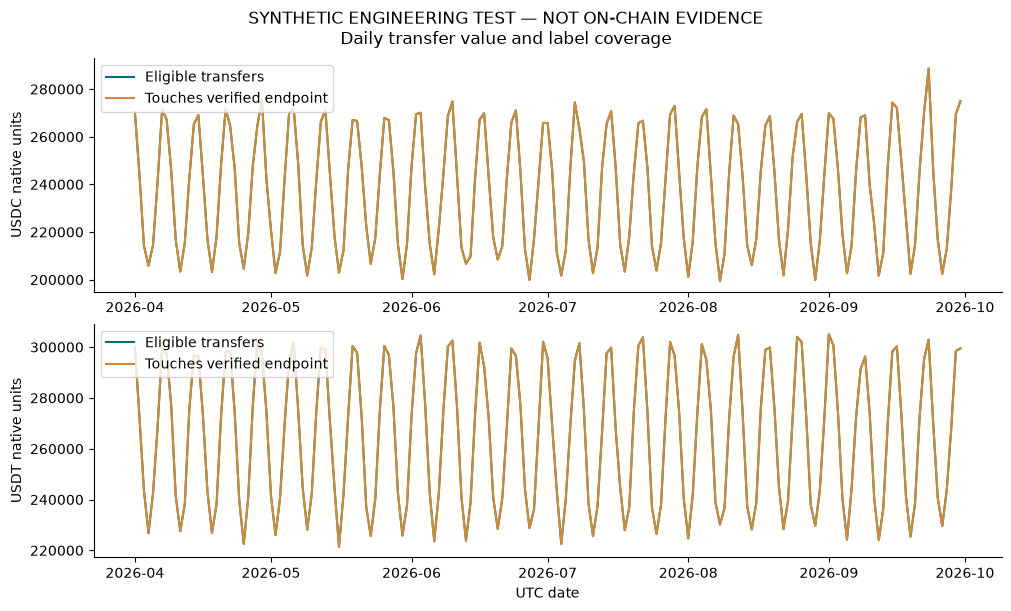

In [2]:
fig, axes = plt.subplots(2,1,figsize=(10,6),layout="constrained")
for ax, token in zip(axes,["USDC","USDT"]):
    rows = [r for r in analysis["totals"] if r["token"]==token and r["complete"]]
    ax.plot([utc(r["date"]) for r in rows],[r["amount"] for r in rows],color="#086f75",label="Eligible transfers")
    ax.plot([utc(r["date"]) for r in rows],[r["known_amount"] for r in rows],color="#cf8b39",label="Touches verified endpoint")
    ax.set_ylabel(token+" native units"); ax.legend(loc="upper left")
axes[-1].set_xlabel("UTC date")
fig.suptitle(notice+"\nDaily transfer value and label coverage")
plt.show()

## Results: final holdout forecast comparison
All references and GRU variants are evaluated on identical target hours. Macro WAPE averages nonzero-denominator token/category/direction groups. These numbers are evidence of software execution when the input is synthetic, and do not establish on-chain predictive performance.

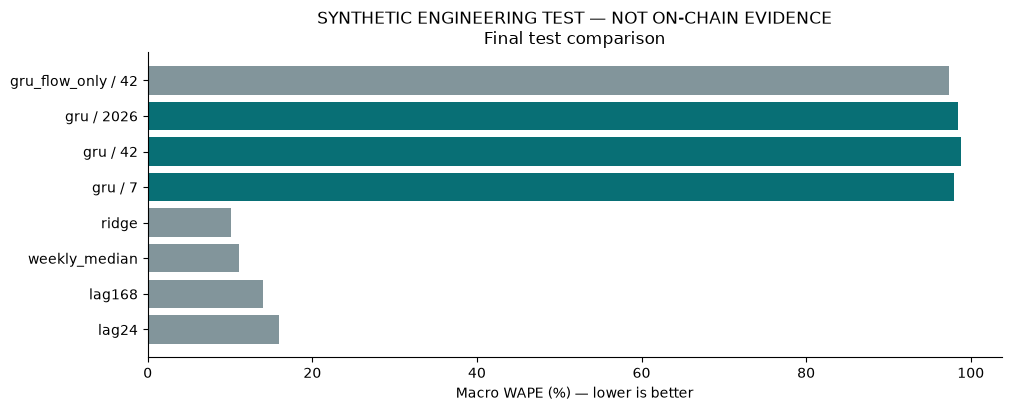

GRU seed variability: {'seeds': [7, 42, 2026], 'test_macro_wape': [0.9791850504450025, 0.9881582563009372, 0.984012842812874]}
Independent anomaly truth labels: unavailable


In [3]:
scores = [r for r in experiment["macro_metrics"] if r["split"]=="test"]
names = [r["model"]+(" / "+str(r["seed"]) if r["seed"] is not None else "") for r in scores]
values = [100*r["macro_wape"] if r["macro_wape"] is not None else 0 for r in scores]
fig, ax = plt.subplots(figsize=(10,4),layout="constrained")
ax.barh(names,values,color=["#086f75" if r["model"]=="gru" else "#82959b" for r in scores])
ax.set_xlabel("Macro WAPE (%) — lower is better")
ax.set_title(notice+"\nFinal test comparison")
plt.show()
print("GRU seed variability:",experiment["seed_variability"])
print("Independent anomaly truth labels: unavailable")

## Takeaways and evidence boundaries
Use the site's evidence view for source versions and transaction investigation status. Fixed-label retrospective performance does not establish live availability or complete exchange coverage. Residual flags become available after the actual hour ends; they do not identify fraud or an attack.

In [4]:
for finding in analysis["findings"]: print(finding)
print("Queued anomaly events:",len(experiment["anomalies"]))
for event in experiment["anomalies"][:3]:
    print(event["token"],event["category"],event["start"],event["investigation"],event.get("evidence_status","pending"))
if synthetic: print("No economic finding is claimed from this notebook.")

Synthetic test data validates the software pipeline; it establishes no on-chain research finding.
Queued anomaly events: 20
USDC dex 2026-09-23T00:00:00Z unexplained available; requires investigation
USDC bridge 2026-09-09T04:00:00Z unexplained available; requires investigation
USDC bridge 2026-09-03T06:00:00Z unexplained available; requires investigation
No economic finding is claimed from this notebook.
